# Travail pratique 4 : Segmentation d'images 2D


### Monter le réperdoire de google drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r drive/MyDrive/tp4/* .

Mounted at /content/drive


### Aller dans le bon répertoire et exécuter le code.



In [2]:
ls

drive/  README.md  requirements.txt  sample_data/  src/


In [3]:
cd src/

/content/src


In [4]:
ls

data/  fig1.png  loss/  manage/  models/  train.ipynb  train.py  utils/


In [5]:
cd ..

/content


In [6]:
!pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 100.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 92.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 92.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [7]:
cd /content/src/

/content/src


In [ ]:
!python train.py --help

### Entraînement d'un UNet

In [16]:
!python train.py --model=UNet --num-epochs=2 --batch_size=32 --lr=0.01

Data augmentation NOT activated!
Training UNet on acdc for 2 epochs
Epoch: 1 of 2
100% 40/40 [01:06<00:00,  1.67s/it, Train loss=1.12, train_acc=0.0228]
Validation loss 1.635
Validation accuracy 0.035
Epoch: 2 of 2
100% 40/40 [01:03<00:00,  1.59s/it, Train loss=0.679, train_acc=0.036]
Validation loss 0.530
Validation accuracy 0.047
Finished training.
Accuracy of the network on the test set: 4.632 %
Figure(1000x1000)
Figure(1000x1000)
Figure(1000x1000)
Figure(1000x500)


In [ ]:
# Le fichier UNet_acc_valid_79.pt contient les poids d'un UNet ayant une justesse de 79%.
!python train.py --model UNet --predict ./UNet_acc_valid_79.pt

### Pour une raison quelconque, matplotlib ne fonctionne pas bien dans google Colab. Par consquent, une autre façon de visualiser les résultats est de sauvegarder les figures et de les afficher par la suite (voir cellule suivante)

In [ ]:
from IPython.display import Image, display

listOfImageNames = ['fig1.png', 'fig2.png', 'fig3.png', 'fig4.png']

for imageName in listOfImageNames:
    display(Image(filename=imageName))

### Entraînement du YourUNet

In [19]:
!python train.py --model=yourUNet --loss=diceCE --num-epochs=20 --batch_size=4 --lr=0.01 --dataset='acdc'

Data augmentation NOT activated!
Training YourUNet on acdc for 20 epochs
Epoch: 1 of 20
100% 320/320 [02:33<00:00,  2.09it/s, Train loss=1.39, train_acc=0.0507]
Validation loss 1.246
Validation accuracy 0.065
Epoch: 2 of 20
100% 320/320 [02:31<00:00,  2.11it/s, Train loss=0.892, train_acc=0.225]
Validation loss 1.350
Validation accuracy 0.151
Epoch: 3 of 20
100% 320/320 [02:31<00:00,  2.11it/s, Train loss=0.677, train_acc=0.408]
Validation loss 0.731
Validation accuracy 0.384
Epoch: 4 of 20
100% 320/320 [02:31<00:00,  2.11it/s, Train loss=0.567, train_acc=0.507]
Validation loss 0.997
Validation accuracy 0.224
Epoch: 5 of 20
100% 320/320 [02:31<00:00,  2.11it/s, Train loss=0.488, train_acc=0.575]
Validation loss 0.644
Validation accuracy 0.499
Epoch: 6 of 20
100% 320/320 [02:31<00:00,  2.11it/s, Train loss=0.448, train_acc=0.609]
Validation loss 1.399
Validation accuracy 0.563
Epoch: 7 of 20
100% 320/320 [02:31<00:00,  2.11it/s, Train loss=0.407, train_acc=0.644]
Validation loss 6.486
V

In [28]:
!python train.py --model=yourUNet --loss=diceCE --num-epochs=20 --batch_size=4 --lr=0.01 --dataset='acdc'

Data augmentation NOT activated!
Training YourUNet on acdc for 20 epochs
Epoch: 1 of 20
100% 320/320 [00:57<00:00,  5.60it/s, Train loss=1.43, train_acc=0.0232]
Validation loss 1.131
Validation accuracy 0.068
Epoch: 2 of 20
100% 320/320 [00:58<00:00,  5.46it/s, Train loss=0.885, train_acc=0.233]
Validation loss 0.766
Validation accuracy 0.341
Epoch: 3 of 20
100% 320/320 [01:00<00:00,  5.30it/s, Train loss=0.529, train_acc=0.536]
Validation loss 0.547
Validation accuracy 0.562
Epoch: 4 of 20
100% 320/320 [01:00<00:00,  5.29it/s, Train loss=0.386, train_acc=0.659]
Validation loss 0.521
Validation accuracy 0.585
Epoch: 5 of 20
100% 320/320 [01:00<00:00,  5.29it/s, Train loss=0.334, train_acc=0.706]
Validation loss 0.319
Validation accuracy 0.727
Epoch: 6 of 20
100% 320/320 [01:00<00:00,  5.30it/s, Train loss=0.303, train_acc=0.732]
Validation loss 0.289
Validation accuracy 0.743
Epoch: 7 of 20
100% 320/320 [01:00<00:00,  5.28it/s, Train loss=0.276, train_acc=0.754]
Validation loss 0.414
V

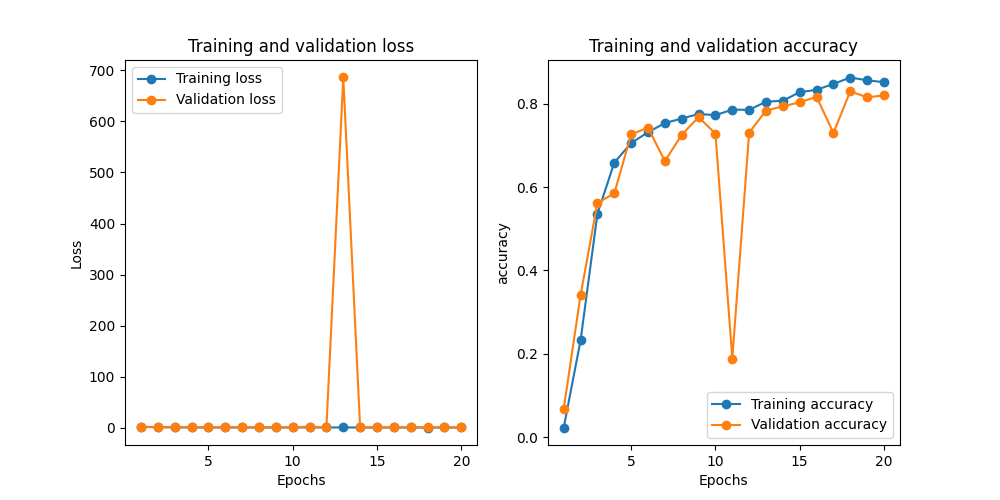

FileNotFoundError: [Errno 2] No such file or directory: 'fig2.png'

In [29]:
from IPython.display import Image, display

listOfImageNames = ['fig1.png', 'fig2.png', 'fig3.png', 'fig4.png']

for imageName in listOfImageNames:
    display(Image(filename=imageName))